# Lab 3 — Millions of TVs, Who Is Watching?
Name: Adelina Khytrenko | Group: KM-43

## Setup

In [1]:
%pip install -q kagglehub pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [3]:
days = pd.date_range('2024-10-14', '2024-10-27')
networks = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC', 'FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']
big = networks[:5]

# Eastern time first, then the broadcast day starting at 06:00
acr_sessions['start_ts'] = acr_sessions['start_utc'].dt.tz_convert('US/Eastern').dt.tz_localize(None)
acr_sessions['end_ts'] = acr_sessions['end_utc'].dt.tz_convert('US/Eastern').dt.tz_localize(None)
acr_sessions['broadcast_date'] = (acr_sessions['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
acr_sessions['duration_sec'] = (acr_sessions['end_ts'] - acr_sessions['start_ts']).dt.total_seconds()

# These repeated strings take less memory as categories
for col in ['session_type', 'network_code', 'input_source']:
    acr_sessions[col] = acr_sessions[col].astype('category')

acr = acr_sessions[acr_sessions['duration_sec'] >= 60].copy()
acr['hours'] = acr['duration_sec'] / 3600
tv_tab = acr.groupby('broadcast_date')['tv_id'].nunique().reindex(days, fill_value=0)

daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date'])
programs['broadcast_date'] = pd.to_datetime(programs['broadcast_date'])
dw = daily_weights[daily_weights['broadcast_date'].isin(days)].copy()
dw_hh = dw[dw['resp_type'] == 'H'].copy()

viewings['broadcast_date'] = (viewings['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
panel = viewings[viewings['broadcast_date'].isin(days)].copy()
panel_hh = panel[(panel['resp_type'] == 'H') & (panel['playback'] == 'Live')].copy()
panel_hh['hours'] = (panel_hh['end_ts'] - panel_hh['start_ts']).dt.total_seconds() / 3600

I assign sessions to the broadcast day when they start, as in Lab 1. The in-tab count includes all session types after the one-minute edit rule, including app and unknown sessions. I use all in-tab TV-days as the denominator for both raw and edited hours.

## Task 1.1 — Five questions

**Answer:**

| Dataset | Grain | Key | Coverage | Weight | Provenance |
|---|---|---|---|---|---|
| `acr_sessions` | One session on one TV | `session_id`; `tv_id` identifies the TV | Opted-in smart TVs, Oct 14–27, 2024; live, DVR, app and unknown activity | No population weight; each TV counts once | Synthetic ACR feed based on screen fingerprint matching |
| Lab 1 `viewings` | One respondent's session on one network; H rows describe household tuning | `viewing_id`; `respondent_id` identifies the household or person | Panel households, members and visitors, October 2024; ten networks, live viewing only | Daily household or person weight | Synthetic people-meter panel, calibrated to US audiences |

For me, the biggest difference is coverage. The ACR file has many more TVs, but it only includes homes that bought a compatible TV and opted in. The panel is intended to represent US households and people, and its weights let us project to that population.

## Task 1.2 — Size and shape

In [4]:
tv_days = tv_tab.sum()
raw_hours = acr_sessions['duration_sec'].sum() / 3600
dropped_share = 1 - len(acr) / len(acr_sessions)

print("TVs:", acr_sessions['tv_id'].nunique())
print("Sessions:", len(acr_sessions))
print("Broadcast days:", acr_sessions['broadcast_date'].nunique())
print("Average TVs in-tab per day:", round(tv_tab.mean(), 1))
print("Hours per TV per day, raw:", f"{raw_hours / tv_days:.2f}")
print("Hours per TV per day, after edit rule:", f"{acr['hours'].sum() / tv_days:.2f}")
print("Share of sessions dropped:", f"{dropped_share:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [5]:
type_share = acr.groupby('session_type', observed=True)['hours'].sum() / acr['hours'].sum()
input_share = acr.groupby('input_source', observed=True)['hours'].sum() / acr['hours'].sum()

display(type_share.rename('share_of_hours').to_frame().round(3))
display(input_share.rename('share_of_hours').to_frame().round(3))
print("Share of TV-on hours unknown (%):", f"{type_share['unknown'] * 100:.1f}")

Share of TV-on hours unknown (%): 39.6


,share_of_hours
session_type,
app,0.257
dvr,0.025
live,0.322
unknown,0.396


,share_of_hours
input_source,
antenna,0.086
built_in_app,0.307
cable_box,0.276
game_or_disc,0.024
satellite_box,0.076
streaming_device,0.231


**Answer:** Unknown activity makes up 39.6% of TV-on hours here, compared with 66% in the real LG example mentioned in the task. A real feed has more varied content and devices, and its reference library cannot cover everything on the screen. For example, a streaming title without a matching fingerprint and a video game or disc can end up as unknown. An unknown session still tells us that the screen was on, but it does not tell us which network or program was watched.

## Task 2.1 — Match

In [6]:
tvs = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates('tv_id').copy()
ip_counts = hh_attributes.groupby('hashed_ip')['household_id'].nunique()
tvs['hh_matches'] = tvs['hashed_ip'].map(ip_counts).fillna(0)

print("Matched to one household (%):", f"{tvs['hh_matches'].eq(1).mean() * 100:.1f}")
print("Shared IP, unresolved (%):", f"{tvs['hh_matches'].gt(1).mean() * 100:.1f}")
print("Not matched (%):", f"{tvs['hh_matches'].eq(0).mean() * 100:.1f}")

unique_hh = hh_attributes[hh_attributes['hashed_ip'].map(ip_counts) == 1]
matched = tvs[tvs['hh_matches'] == 1].merge(
    unique_hh, on='hashed_ip', how='left', validate='many_to_one'
)

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP identifies an internet connection, which is not always one household. Several homes can share an address, and a household's IP can change or be recorded at a different time in the consumer file. Hashing hides the original address but does not make it a better key. I leave shared IPs unresolved instead of choosing a household at random.

## Task 2.2 — Profile

In [7]:
# One household, one average weight over its in-tab days in these two weeks
panel_profile = dw_hh.groupby('respondent_id')['weight'].mean().rename('weight').to_frame()
attr_labels = viewer_attributes.merge(attributes[['attr_id', 'attr_group', 'attr_name']], on='attr_id')

for group, col in [('Census region', 'region'), ('Household income', 'income_band')]:
    labels = attr_labels[attr_labels['attr_group'] == group].set_index('respondent_id')['attr_name']
    panel_profile[col] = panel_profile.index.map(labels)

income_groups = {
    'Under $25k': 'Under $50k', '$25k-$50k': 'Under $50k',
    '$50k-$75k': '$50-100k', '$75k-$100k': '$50-100k',
    '$100k-$150k': '$100k+', '$150k+': '$100k+'
}
matched['income_group'] = matched['income_band'].map(income_groups)
panel_profile['income_group'] = panel_profile['income_band'].map(income_groups)

def profile_table(col, order):
    footprint = matched[col].value_counts(normalize=True).reindex(order)
    panel_share = panel_profile.groupby(col, observed=True)['weight'].sum().reindex(order) / panel_profile['weight'].sum()
    return pd.DataFrame({
        'footprint_share': footprint,
        'panel_share': panel_share,
        'index': footprint / panel_share * 100
    }).rename_axis('group')

region_profile = profile_table('region', ['Northeast', 'Midwest', 'South', 'West'])
income_profile = profile_table('income_group', ['Under $50k', '$50-100k', '$100k+'])
display(region_profile.round({'footprint_share': 3, 'panel_share': 3, 'index': 1}))
display(income_profile.round({'footprint_share': 3, 'panel_share': 3, 'index': 1}))

,footprint_share,panel_share,index
group,,,
Northeast,0.150,0.170,88.0
Midwest,0.201,0.210,96.0
South,0.383,0.379,101.0
West,0.266,0.241,110.4


,footprint_share,panel_share,index
group,,,
Under $50k,0.259,0.361,71.8
$50-100k,0.320,0.289,110.8
$100k+,0.421,0.350,120.1


In [8]:
# Check the age idea from the hint using the panel's head of household
age = viewer_attributes[viewer_attributes['attr_id'] == 300].set_index('respondent_id')['value']
heads = viewer_attributes[viewer_attributes['attr_id'] == 701].copy()
heads['head_age'] = heads['respondent_id'].map(age)
heads['hh_id'] = (heads['respondent_id'] // 100) * 100
head_age = heads.set_index('hh_id')['head_age']

panel_profile['head_age_band'] = pd.cut(
    panel_profile.index.map(head_age), bins=[18, 35, 50, 65, np.inf],
    labels=['18-34', '35-49', '50-64', '65+'], right=False
)
age_profile = profile_table('head_age_band', ['18-34', '35-49', '50-64', '65+'])
display(age_profile.round({'footprint_share': 3, 'panel_share': 3, 'index': 1}))

,footprint_share,panel_share,index
group,,,
18-34,0.196,0.190,103.6
35-49,0.348,0.303,115.0
50-64,0.263,0.240,109.6
65+,0.192,0.267,71.8


**Answer:** The matched footprint over-represents the West (index 110.4) and under-represents the Northeast (88.0), while the South and Midwest are closer to the panel. The income difference is larger: under-$50k homes have an index of 71.8, compared with 120.1 for $100k+ homes. The age check also shows too few homes with a head aged 65+ (index 71.8), while the 35–49 and 50–64 groups are over-represented. One possible reason is that higher-income, younger households are more likely to own a newer connected TV and agree to its data collection. These profiles describe only the 65.2% of TVs that matched one household, so the unmatched part may have a different profile.

## Task 2.3 — Ratings

In [9]:
# Add all overlaps for each TV/person, then apply the one-minute rule
def watched_ids(sessions, telecast, id_col):
    s = sessions[
        (sessions['network_code'] == telecast['network_code']) &
        (sessions['start_ts'] < telecast['end_ts']) &
        (sessions['end_ts'] > telecast['start_ts'])
    ].copy()
    start = s['start_ts'].clip(lower=telecast['start_ts'])
    end = s['end_ts'].clip(upper=telecast['end_ts'])
    seconds = (end - start).dt.total_seconds().groupby(s[id_col]).sum()
    return seconds[seconds >= 60].index

live = acr[acr['session_type'] == 'live'].copy()
ratings = reference_ratings.merge(programs, on='telecast_id', validate='one_to_one')
ratings['telecast'] = ratings['program_name'].replace({
    'NFL Football': 'Sunday Night Football', 'MLB Postseason': 'World Series Game 1'
})
tv_ratings = []

for _, telecast in ratings.iterrows():
    day = telecast['broadcast_date']
    sessions = live[live['broadcast_date'] == day]
    viewers = watched_ids(sessions, telecast, 'tv_id')
    tv_ratings.append(len(viewers) / tv_tab.loc[day] * 100)

ratings['tv_hh_rating'] = tv_ratings
ratings['ratio'] = ratings['tv_hh_rating'] / ratings['hh_rating']
ratings['gap_pp'] = ratings['tv_hh_rating'] - ratings['hh_rating']

display(ratings[['telecast', 'network_code', 'broadcast_date', 'tv_hh_rating', 'hh_rating', 'ratio']]
        .round({'tv_hh_rating': 1, 'hh_rating': 1, 'ratio': 3}))

,telecast,network_code,broadcast_date,tv_hh_rating,hh_rating,ratio
0,World Series Game 1,FOX,2024-10-25,16.5,25.9,0.639
1,Sunday Night Football,NBC,2024-10-27,21.2,33.1,0.641
2,NCIS,CBS,2024-10-14,5.4,10.6,0.509
3,Hannity,FNC,2024-10-16,0.8,2.3,0.359
4,Unsellable Houses,HGTV,2024-10-16,2.1,3.7,0.568
5,Halloween Baking Championship,FOOD,2024-10-14,1.0,1.6,0.604
6,Grotesquerie,FX,2024-10-16,2.3,3.5,0.641
7,The Real Housewives of New York City,BRAVO,2024-10-15,0.7,1.2,0.600


**Answer:** All eight TV ratings are below the reference. Relative to the reference, Hannity is furthest off (ratio 0.359), followed by NCIS (0.509); Sunday Night Football and Grotesquerie are closest, both around 0.641. In rating points, Sunday Night Football has the largest gap (11.9 points), while The Real Housewives of New York City has the smallest (0.5 points). The relatively weak Hannity and NCIS results fit the shortage of older households, although the profile alone does not prove the cause. Measuring only one set and failing to recognize some viewing can also lower ratings across programs. I would not fix all eight ratings with one multiplier because the relative gaps differ.

## Task 3.1 — Hours per home

In [10]:
live_ten = live[live['network_code'].isin(networks)].copy()

# Daily panel weights also include homes that did not watch these networks
panel_hh = panel_hh.drop(columns='weight').merge(
    dw_hh[['respondent_id', 'broadcast_date', 'weight']],
    on=['respondent_id', 'broadcast_date'], how='inner', validate='many_to_one'
)
panel_hh['weighted_hours'] = panel_hh['hours'] * panel_hh['weight']

tv_hours = live_ten['hours'].sum() / tv_days
hh_hours = panel_hh['weighted_hours'].sum() / dw_hh['weight'].sum()

print("Live hours per TV per day (ten networks):", f"{tv_hours:.2f}")
print("Live hours per panel household per day (ten networks):", f"{hh_hours:.2f}")
print("Difference (hours):", f"{hh_hours - tv_hours:.2f}")
print("TV hours lower than panel (%):", f"{(1 - tv_hours / hh_hours) * 100:.1f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Difference (hours): 1.05
TV hours lower than panel (%): 54.8


**Answer:** The TVs record 0.87 live hours per day on the ten networks, compared with 1.92 hours per panel household. That is 1.05 hours, or 54.8%, lower. One observed TV does not cover all the sets in a home: the lecture gives about 2.6 sets per household, with only about 1.1 of the same brand. The footprint also has a different mix of homes, and unrecognized viewing cannot count toward a network's live hours. I would not simply multiply by 2.6, since sets are used differently and can be on at the same time.

## Task 3.2 — Network shares

In [11]:
tv_net = live_ten.groupby('network_code', observed=True)['hours'].sum().reindex(networks)
panel_net = panel_hh.groupby('network_code')['weighted_hours'].sum().reindex(networks)

network_shares = pd.DataFrame({
    'TV_share': tv_net / tv_net.sum(),
    'panel_share': panel_net / panel_net.sum()
})
network_shares['difference_pp'] = (network_shares['TV_share'] - network_shares['panel_share']) * 100
display(network_shares.round({'TV_share': 3, 'panel_share': 3, 'difference_pp': 1}))

,TV_share,panel_share,difference_pp
network_code,,,
CBS,0.182,0.196,-1.4
NBC,0.214,0.206,0.7
ABC,0.196,0.187,0.9
FOX,0.201,0.194,0.8
FNC,0.085,0.110,-2.5
FX,0.028,0.022,0.6
BRAVO,0.016,0.013,0.3
HGTV,0.034,0.031,0.3
FOOD,0.024,0.022,0.2


**Answer:** FNC is under-stated most, by 2.5 percentage points of the ten-network viewing share, followed by CBS at 1.4 points. The other eight networks have higher shares in the TVs, especially ABC, FOX and NBC. FX and Bravo also take a larger share than in the panel, which fits the younger household profile. These are shares within the ten networks, so a higher share does not mean the feed captures more total viewing hours.

## Task 3.3 — What each can see

**Answer:** The panel can identify which people watched, calculate person demographics such as A25–54, and measure household tuning across the home's measured sets. Its daily weights also include homes that watched none of the ten networks.

The ACR file can record live viewing on networks outside the ten-network panel extract, separate live and DVR sessions, and show TV-on activity by input, including apps and unknown content. It can tell that an app was used, but this file does not identify the title or the people watching it.

## Task 4.1 — Daily plots

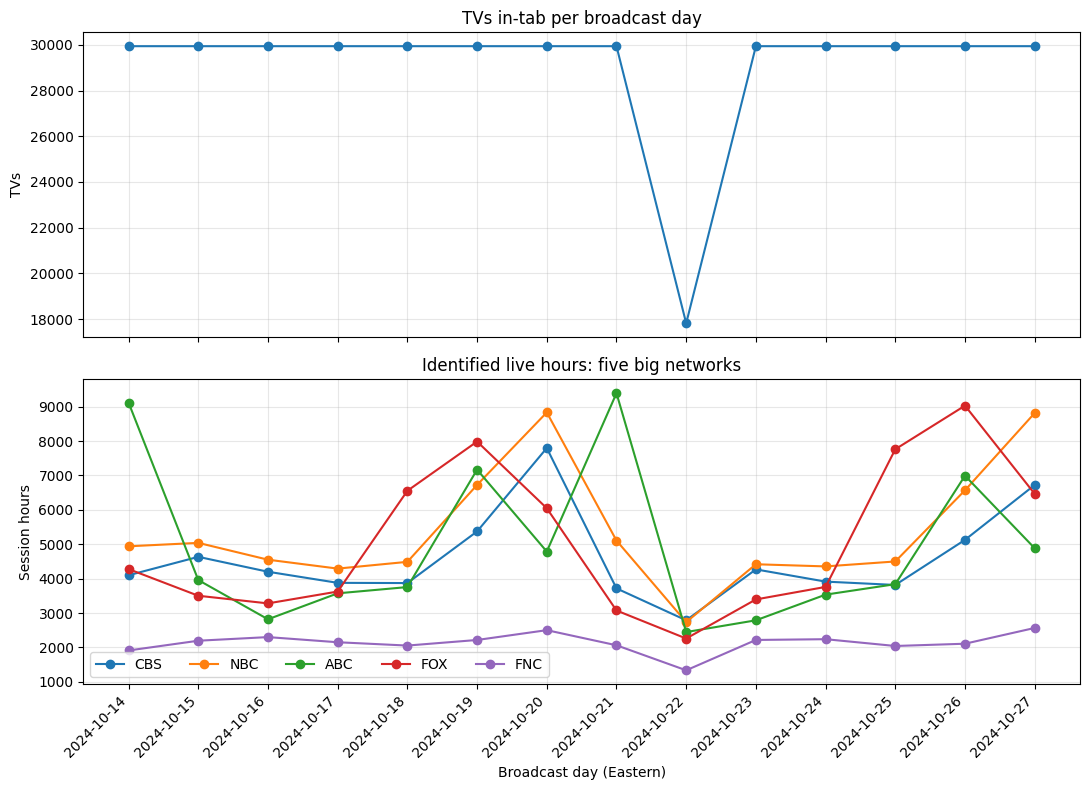

In [12]:
daily_live = live[live['network_code'].isin(big)].groupby(
    ['broadcast_date', 'network_code'], observed=True
)['hours'].sum().unstack(fill_value=0).reindex(index=days, columns=big, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].plot(days, tv_tab, marker='o')
axes[0].set_title('TVs in-tab per broadcast day')
axes[0].set_ylabel('TVs')
axes[0].grid(alpha=0.3)

for net in big:
    axes[1].plot(days, daily_live[net], marker='o', label=net)
axes[1].set_title('Identified live hours: five big networks')
axes[1].set_ylabel('Session hours')
axes[1].set_xlabel('Broadcast day (Eastern)')
axes[1].legend(ncol=5)
axes[1].grid(alpha=0.3)
axes[1].set_xticks(days)
axes[1].set_xticklabels(days.strftime('%Y-%m-%d'), rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [13]:
spike_day, spike_net = daily_live.stack().idxmax()
broken_day = tv_tab.idxmin()

print("Biggest spike (date, network):", spike_day.strftime('%Y-%m-%d'), spike_net)
print("Broken day (date):", broken_day.strftime('%Y-%m-%d'))

# Which programs contributed most to that network's hours?
spike_programs = programs[
    (programs['broadcast_date'] == spike_day) & (programs['network_code'] == spike_net)
].copy()
spike_sessions = live[(live['broadcast_date'] == spike_day) & (live['network_code'] == spike_net)]
program_hours = []
for _, p in spike_programs.iterrows():
    overlap = spike_sessions[
        (spike_sessions['start_ts'] < p['end_ts']) & (spike_sessions['end_ts'] > p['start_ts'])
    ]
    seconds = (overlap['end_ts'].clip(upper=p['end_ts']) -
               overlap['start_ts'].clip(lower=p['start_ts'])).dt.total_seconds()
    program_hours.append(seconds.sum() / 3600)
spike_programs['live_hours'] = program_hours
display(spike_programs[['program_name', 'episode_name', 'start_ts', 'live_hours']]
        .sort_values('live_hours', ascending=False).head(5).round({'live_hours': 2}))

daily_check = pd.DataFrame({
    'TVs_in_tab': tv_tab,
    'all_hours': acr.groupby('broadcast_date')['hours'].sum(),
    'identified_live_hours': live.groupby('broadcast_date')['hours'].sum()
})
daily_check['all_hours_per_TV'] = daily_check['all_hours'] / tv_tab
daily_check['live_hours_per_TV'] = daily_check['identified_live_hours'] / tv_tab
display(daily_check.round(2))

Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22


,program_name,episode_name,start_ts,live_hours
282,NFL Football,NFL Football: BAL @ TB,2024-10-21 20:15:00,6991.21
278,Local / Syndicated Programming,None,2024-10-21 15:00:00,419.78
272,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",2024-10-21 07:00:00,291.04
280,Local / Syndicated Programming,None,2024-10-21 19:00:00,247.05
283,Local / Syndicated Programming,None,2024-10-21 23:25:00,242.33


,TVs_in_tab,all_hours,identified_live_hours,all_hours_per_TV,live_hours_per_TV
2024-10-14,29940,135257.43,44053.79,4.52,1.47
2024-10-15,29940,133543.88,42258.27,4.46,1.41
2024-10-16,29940,133115.80,42234.83,4.45,1.41
2024-10-17,29940,131951.90,42064.60,4.41,1.40
2024-10-18,29940,131460.60,41482.00,4.39,1.39
2024-10-19,29940,158983.42,51646.62,5.31,1.73
2024-10-20,29940,159161.69,51734.51,5.32,1.73
2024-10-21,29940,136378.94,44816.99,4.56,1.50
2024-10-22,17818,79258.87,25107.75,4.45,1.41
2024-10-23,29940,133025.46,42348.24,4.44,1.41


**Answer:** The biggest spike is ABC on 2024-10-21. The schedule shows Monday Night Football, Baltimore at Tampa Bay, starting at 20:15; that telecast contributes about 6,991.21 identified live hours.

The broken day is 2024-10-22: in-tab TVs fall from the usual 29,940 to 17,818, a drop of 40.5%, and return the next day. Hours per reporting TV stay close to the surrounding weekdays (4.45 total hours and 1.41 identified live hours), which suggests missing reporting rather than a sudden audience change. The files do not tell us the exact technical cause. Daily totals would be too low, and using the usual 29,940 denominator would also push ratings down. Using the actual in-tab denominator helps if the missing TVs are random, but it cannot remove bias if certain homes are missing more often. I would flag the day and ask for the missing records to be recovered; if that is impossible, I would exclude it from client comparisons rather than silently scale it up.

## Task 5.1 — Sampling error vs bias

In [14]:
names = ['Sunday Night Football', 'Hannity', 'Unsellable Houses']
errors = ratings[ratings['telecast'].isin(names)].copy()
hh_tab = dw_hh.groupby('broadcast_date')['respondent_id'].nunique()

errors['n_TV'] = errors['broadcast_date'].map(tv_tab)
errors['n_panel'] = errors['broadcast_date'].map(hh_tab)
p = errors['hh_rating'] / 100
errors['SE_TV_pp'] = np.sqrt(p * (1 - p) / errors['n_TV']) * 100
errors['SE_panel_pp'] = np.sqrt(p * (1 - p) / errors['n_panel']) * 100
errors['SE_panel_div_TV'] = errors['SE_panel_pp'] / errors['SE_TV_pp']

display(errors[['telecast', 'n_TV', 'n_panel', 'SE_TV_pp', 'SE_panel_pp',
                'SE_panel_div_TV', 'gap_pp']].round({
    'SE_TV_pp': 1, 'SE_panel_pp': 1, 'SE_panel_div_TV': 3, 'gap_pp': 1
}))

,telecast,n_TV,n_panel,SE_TV_pp,SE_panel_pp,SE_panel_div_TV,gap_pp
1,Sunday Night Football,29940,3898,0.3,0.8,2.771,-11.9
3,Hannity,29940,3867,0.1,0.2,2.783,-1.5
4,Unsellable Houses,29940,3867,0.1,0.3,2.783,-1.6


**Answer:** Using the requested formula, the footprint's standard errors are about 2.8 times smaller than the panel's, or roughly 64% lower. However, its rating gaps are much larger: 11.9 points for Sunday Night Football, 1.5 for Hannity and 1.6 for Unsellable Houses. Even the largest footprint SE is only 0.3 points after rounding. The main problem here is systematic error from the footprint and its measurement coverage, rather than sampling noise. More TVs reduce random error but do not automatically correct who is missing or what is not measured. These SEs are a simple random-sample benchmark; the formula does not account for the panel's unequal weights or turn an opted-in footprint into a random sample.

## Task 5.2 — Answer to the planner

**Answer:** Today I can report an unweighted 21.2% rating among in-tab TVs for NBC's Dallas–San Francisco game on 2024-10-27. The reference household rating is 33.1%, so I would label our result as a footprint measure rather than use it as a US estimate. The feed records devices and cannot identify individual viewers or capture other TV sets in the same home. It records app activity without identifying titles, and it misses homes that did not opt in or have a compatible TV. Unmatched and shared-IP TVs still contribute to the overall rating, but we cannot reliably attach household demographics to them. Before using it for planning, I would want the missing-day issue explained, the footprint calibrated to a representative panel, multi-set and content coverage assessed, and adjusted results checked against the reference.

## Bonus

In [15]:
snf = ratings[ratings['telecast'] == 'Sunday Night Football'].iloc[0]
day = snf['broadcast_date']
day_weights = dw[dw['broadcast_date'] == day].copy()
day_weights['age'] = day_weights['respondent_id'].map(age)

hh_weights = day_weights[day_weights['resp_type'] == 'H'].set_index('respondent_id')['weight']
target_weights = day_weights[
    day_weights['resp_type'].isin(['R', 'L']) & day_weights['age'].between(25, 54)
].set_index('respondent_id')['weight']

day_viewing = panel[(panel['broadcast_date'] == day) & (panel['playback'] == 'Live')]
hh_viewers = watched_ids(day_viewing[day_viewing['resp_type'] == 'H'], snf, 'respondent_id')
person_viewers = watched_ids(day_viewing[day_viewing['resp_type'].isin(['R', 'L'])], snf, 'respondent_id')

hh_audience = hh_weights.loc[hh_weights.index.isin(hh_viewers)].sum()
target_audience = target_weights.loc[target_weights.index.isin(person_viewers)].sum()
vpvh = target_audience / hh_audience
universe_hh = hh_weights.sum()
universe_target = target_weights.sum()
target_rating = snf['tv_hh_rating'] * vpvh * universe_hh / universe_target

print("VPVH A25-54:", f"{vpvh:.3f}")
print("A25-54 rating (persons):", f"{target_rating:.1f}")
print("US TV households:", universe_hh)
print("US A25-54 persons:", universe_target)

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
US TV households: 125800789
US A25-54 persons: 123738777


**Answer:** The weighted panel VPVH is 0.513 A25–54 viewers per viewing household, giving an estimated A25–54 rating of 11.1%. This assumes that the footprint's viewing homes have the same A25–54 viewers per viewing household as the panel for this telecast, including a similar pattern of watching together. That is a strong assumption because the household profiles differ. The calculation also carries over the footprint's household-rating bias, so it is an estimate based on a panel conversion, not directly measured person viewing.